# Keypoint Detection — Main Evaluation (Quarter-Based)

Main-evaluation notebook for Ch. 6 — answers RQ2 (registration accuracy) and RQ3
(optimization) using the quarter-based 4-fold cross-validation adopted after the
cross-stadium generalization attempts in `additional_experiments_evaluation.ipynb`
plateaued (see that notebook's Synthesis section).

Plot style/colors match `Player_Detection/evaluation.ipynb` for visual consistency
across the thesis's two evaluation notebooks.

Each section follows **Method / Results / Discussion**, same convention as the
additional-experiments notebook.

---

## Fold design

Each TB2026 game quarter (Q1-Q4) is held out in turn; the model trains on the other
three. Quarter boundaries come from the QTR column in `tb2026_dataset_metadata.csv`.

| Fold | Clips | Frames |
|------|-------|--------|
| Q1 | 7-39    | 744 |
| Q2 | 40-76   | 652 |
| Q3 | 77-105  | 748 |
| Q4 | 107-144 | 776 |

Lives in `Field_Keypoint_Detection/evaluation/` — run with its working directory
set there (default when opened directly in Jupyter/VS Code); reads results from
`Field_Keypoint_Detection/*_results/` one level up.


## Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor':  'white',
    'axes.facecolor':    'white',
    'savefig.facecolor': 'white',
})

BASE = Path('..')               # Field_Keypoint_Detection/ — where *_results/ live
OUT  = Path('.') / 'evaluation_output'  # evaluation/evaluation_output/
OUT.mkdir(exist_ok=True)

QUARTERS = ['Q1', 'Q2', 'Q3', 'Q4']
LEVELS   = ['0.5Q', '1.0Q', '1.5Q', '2.0Q', '2.5Q', '3.0Q']

# Same flat-UI palette as Player_Detection/evaluation.ipynb, roles assigned by
# entity (never re-cycled): resolution pair, quarter identity, init-strategy pair.
RES_COLORS  = {640: '#4C9BE8', 1280: '#E85C4C'}
QTR_COLORS  = {'Q1': '#3498db', 'Q2': '#e74c3c', 'Q3': '#2ecc71', 'Q4': '#f39c12'}
INIT_COLORS = {'coco': '#95a5a6', 'finetune': '#9b59b6'}


def load_json(path):
    """Returns parsed JSON or None if the file doesn't exist (incomplete/pending run)."""
    p = BASE / path
    return json.loads(p.read_text()) if p.exists() else None


def kpt_overall(path):
    """overall block of a kpt_eval.json (det_rate, mean/median/p90 pixel error)."""
    d = load_json(path)
    return d['overall'] if d else None


## 1. Resolution Comparison — 640px vs. 1280px

**Method.** `quarter_kfold_training.py` — quarter-based 4-fold CV, COCO-pretrained
init, trained at both 640px and 1280px. This is the baseline configuration the rest
of this chapter builds on.

**Why.** Establishes which resolution to standardize on before running the
data-scaling and initialization-strategy comparisons below.


In [2]:
rows = []
for res in [640, 1280]:
    for q in QUARTERS:
        o = kpt_overall(f'quarter_kfold_results_{res}/{q}/kpt_eval.json')
        rows.append({'Resolution': res, 'Quarter': q, **o} if o else
                    {'Resolution': res, 'Quarter': q})
df_res = pd.DataFrame(rows)

summary = df_res.groupby('Resolution')[['det_rate', 'mean_err_px', 'med_err_px']].mean()
summary.index.name = 'Resolution (avg over folds)'
display(df_res.set_index(['Resolution', 'Quarter'])[['det_rate', 'mean_err_px', 'med_err_px']])
display(summary)


det_rate  mean_err_px  med_err_px
Resolution Quarter                                   
640        Q1         0.6003        39.58        8.32
           Q2         0.4562        19.94       12.35
           Q3         0.4114        55.17       25.72
           Q4         0.5054        47.69       25.81
1280       Q1         0.8797        55.64        8.40
           Q2         0.8107       131.04       13.61
           Q3         0.9302        29.23        9.98
           Q4         0.9180        22.46       10.92

,det_rate,mean_err_px,med_err_px
Resolution (avg over folds),,,
640,0.493325,40.5950,18.0500
1280,0.884650,59.5925,10.7275


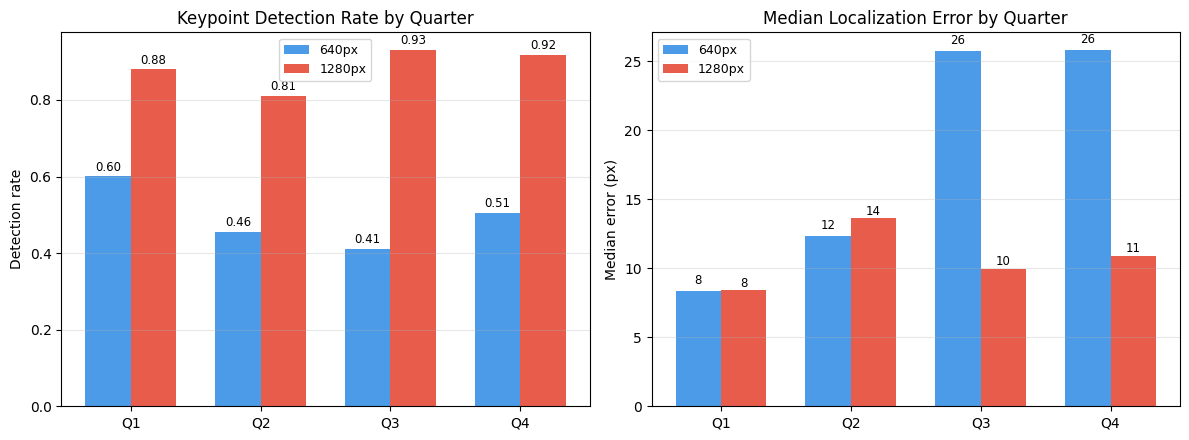

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(QUARTERS))
width = 0.35

for metric, ax, ylabel, title in [
    ('det_rate',    axes[0], 'Detection rate', 'Keypoint Detection Rate by Quarter'),
    ('med_err_px',  axes[1], 'Median error (px)', 'Median Localization Error by Quarter'),
]:
    for res, offset in [(640, -width/2), (1280, width/2)]:
        sub = df_res[df_res['Resolution'] == res].set_index('Quarter').reindex(QUARTERS)
        bars = ax.bar(x + offset, sub[metric], width, label=f'{res}px', color=RES_COLORS[res])
        for xi, v in zip(x + offset, sub[metric]):
            if pd.notna(v):
                ax.text(xi, v + (0.015 if metric == 'det_rate' else sub[metric].max() * 0.02),
                        f'{v:.2f}' if metric == 'det_rate' else f'{v:.0f}',
                        ha='center', fontsize=8.5)
    ax.set_xticks(x); ax.set_xticklabels(QUARTERS)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'resolution_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


**Discussion.**
- 1280px wins clearly and consistently across every fold — avg det_rate 0.885 vs.
  0.493 at 640px. Median error is comparable or better at 1280px too.
- [ ] Note the compute-time cost of 1280px vs 640px if relevant to your methods
  section (training/inference time trade-off).
- **Decision**: 1280px is used as the resolution for all further comparisons in this
  chapter (Sections 2-3 below).


## 2. Data-Scaling Learning Curve (within-fold)

**Method.** `quarter_lc_training.py`, 1280px — for each held-out quarter, training
set size is increased in half-quarter increments (0.5Q -> 3.0Q, i.e. the full 3
training quarters) without ever splitting a clip mid-way. Validation is always the
single held-out quarter, fixed across all levels.

**Why.** Shows how much in-domain (TB2026) data is actually needed per fold, and
whether the amount of data available already saturates performance.


In [4]:
rows = []
for q in QUARTERS:
    for lvl in LEVELS:
        o = kpt_overall(f'quarter_lc_results_1280/{q}/{lvl}/kpt_eval.json')
        if o:
            rows.append({'Quarter': q, 'Level': lvl, **o})
df_lc = pd.DataFrame(rows)
df_lc.pivot(index='Level', columns='Quarter', values='det_rate').reindex(LEVELS)


Quarter,Q1,Q2,Q3,Q4
Level,,,,
0.5Q,0.7303,0.7517,0.6503,0.7622
1.0Q,0.8245,0.7360,0.5439,0.5592
1.5Q,0.8678,0.8258,0.8257,0.8145
2.0Q,0.8798,0.8014,0.8583,0.8542
2.5Q,0.9146,0.8075,0.8777,0.9152
3.0Q,0.8614,0.8107,0.9302,0.9203


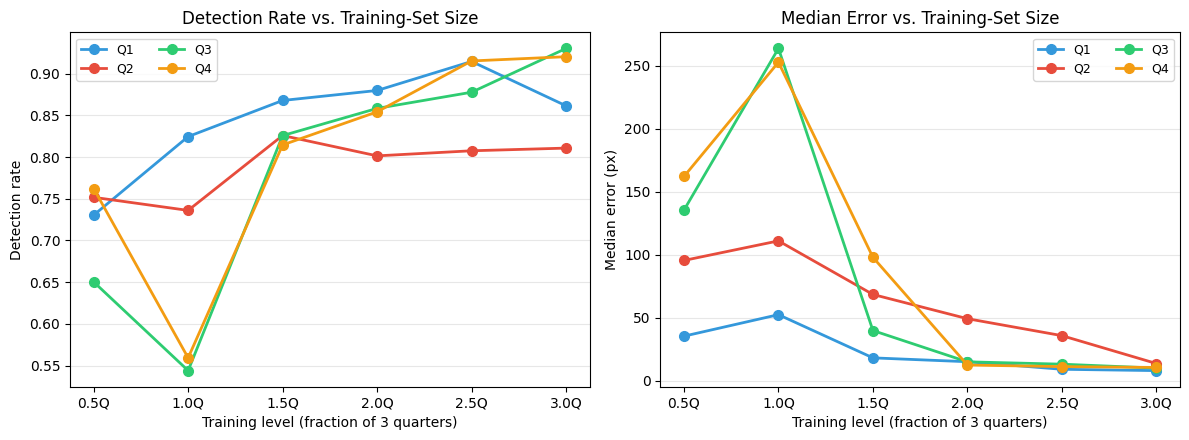

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(LEVELS))

for q in QUARTERS:
    sub = df_lc[df_lc['Quarter'] == q].set_index('Level').reindex(LEVELS)
    axes[0].plot(x, sub['det_rate'], marker='o', color=QTR_COLORS[q],
                 linewidth=2, markersize=7, label=q)
    axes[1].plot(x, sub['med_err_px'], marker='o', color=QTR_COLORS[q],
                 linewidth=2, markersize=7, label=q)

for ax, ylabel, title in [
    (axes[0], 'Detection rate', 'Detection Rate vs. Training-Set Size'),
    (axes[1], 'Median error (px)', 'Median Error vs. Training-Set Size'),
]:
    ax.set_xticks(x); ax.set_xticklabels(LEVELS)
    ax.set_xlabel('Training level (fraction of 3 quarters)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=9, ncol=2)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'quarter_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()


**Discussion.**
- All four folds trend upward with more data, though noisily — e.g. Q3/Q4 dip at
  1.0Q before climbing steadily from 1.5Q onward.
- 3.0Q (full 3-quarter training set) matches the corresponding fold's
  `quarter_kfold_results_1280` number from Section 1, as expected (same training
  data, same architecture) — a useful sanity check that both scripts agree.
- [ ] Discuss whether performance has saturated by 3.0Q or whether more TB2026 data
  (more games) would likely still help.


## 3. Initialization Strategy — COCO-Pretrained vs. Cross-Stadium Fine-Tune

**Method.** Same training data (3 TB2026 quarters) and same 1280px resolution, only
the starting weights differ:
- `quarter_kfold_training.py` (Section 1's baseline): starts from `yolo11l-pose.pt`
  (COCO pretrained).
- `finetune_quarter_training.py`: starts from Stage-3 cross-stadium weights
  (condition1 -> ravelin2025 fine-tuned, see additional-experiments Section 1).

**Why.** Tests whether the external-stadium pretraining explored in the additional
experiments chapter still helps once TB2026-specific quarter folds are used for
training, i.e. does the "expensive" cross-stadium pipeline pay for itself.


In [6]:
rows = []
for q in QUARTERS:
    coco  = kpt_overall(f'quarter_kfold_results_1280/{q}/kpt_eval.json')
    finet = kpt_overall(f'finetune_quarter_results_1280/{q}/kpt_eval.json')
    rows.append({'Quarter': q, 'Init': 'coco',     **(coco or {})})
    rows.append({'Quarter': q, 'Init': 'finetune', **(finet or {})})
df_init = pd.DataFrame(rows)

df_init.set_index(['Quarter', 'Init'])[['det_rate', 'mean_err_px', 'med_err_px']]


det_rate  mean_err_px  med_err_px
Quarter Init                                       
Q1      coco        0.8797        55.64        8.40
        finetune    0.8663        47.78        9.00
Q2      coco        0.8107       131.04       13.61
        finetune    0.8224        21.01        7.87
Q3      coco        0.9302        29.23        9.98
        finetune    0.8416        28.62        9.52
Q4      coco        0.9180        22.46       10.92
        finetune    0.9080        29.72        8.00

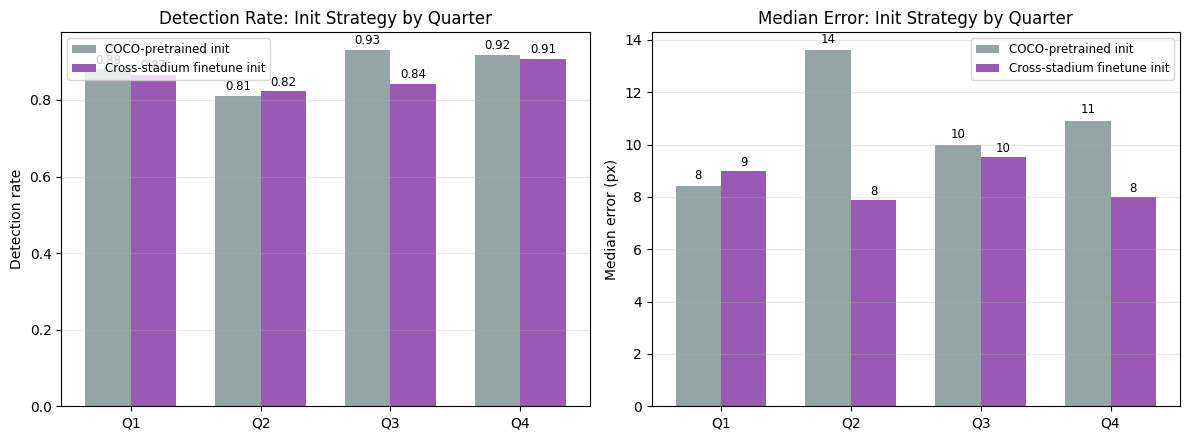

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(QUARTERS))
width = 0.35

for metric, ax, ylabel, title in [
    ('det_rate',   axes[0], 'Detection rate',   'Detection Rate: Init Strategy by Quarter'),
    ('med_err_px', axes[1], 'Median error (px)', 'Median Error: Init Strategy by Quarter'),
]:
    for init, offset, label in [('coco', -width/2, 'COCO-pretrained init'),
                                 ('finetune', width/2, 'Cross-stadium finetune init')]:
        sub = df_init[df_init['Init'] == init].set_index('Quarter').reindex(QUARTERS)
        bars = ax.bar(x + offset, sub[metric], width, label=label, color=INIT_COLORS[init])
        for xi, v in zip(x + offset, sub[metric]):
            if pd.notna(v):
                ax.text(xi, v + (0.015 if metric == 'det_rate' else sub[metric].max(skipna=True) * 0.02),
                        f'{v:.2f}' if metric == 'det_rate' else f'{v:.0f}',
                        ha='center', fontsize=8.5)
    ax.set_xticks(x); ax.set_xticklabels(QUARTERS)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8.5)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'init_strategy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


**Discussion.**
- All 4 folds now complete. Averaged over folds, COCO-init has a slightly *higher*
  det_rate (0.885) than finetune-init (0.860), but finetune-init has a clearly
  *lower* localization error (mean 31.8px vs 59.6px; median 8.6px vs 10.7px).
- Per-fold det_rate: COCO-init is equal-or-ahead on Q1, Q3, Q4; only Q2 favors
  finetune-init. The det_rate gap is driven almost entirely by Q3 (0.930 vs 0.842).
- The mean-error gap is driven substantially by Q2, where COCO-init has a large
  mean-error outlier (131px) not reflected in its own median (13.6px) — points to a
  subset of badly-mislocalized keypoints in that fold rather than a systematic
  offset, worth a sanity check before over-interpreting the mean numbers.
- [ ] Judgment call for the thesis: cross-stadium pretraining does not reliably
  raise detection rate (and slightly hurts it on average) but does tighten
  localization once a keypoint is found. Decide whether that trade-off justifies
  the extra pipeline stage, or whether the simpler COCO-init baseline is the
  recommended configuration (ties into the additional-experiments chapter's
  conclusion that cross-stadium data alone plateaus below the quarter-based floor).


### 3b. Extended Ladder — Including Cross-Stadium Baselines (Stages 2, 3, Combined)

**Method.** Extends the comparison above backward to include the cross-stadium-only
baselines (Stage 2: condition1 only; Stage 3: condition1 -> ravelin2025; Combined:
joint training), each scored on the full tb2026 test set (2920 frames) since none
of them ever see tb2026 during training — there's no fold to hold out for these.
Produces the full five-stage progression (2, 3, Combined, 4a, 4b) referenced in the
thesis's Keypoint Detection Evaluation Results paragraph.

**Why.** Sections above only compare the two target-domain init strategies (4a vs.
4b). Without the baselines, there's no way to see how much of the accuracy comes
from target-domain data at all, versus which weights that fine-tuning starts from.


In [8]:
LADDER_STAGES = ['2', '3', 'Combined', '4a', '4b']
LADDER_LABELS = {
    '2':        'Stage 2\ncondition1 only',
    '3':        'Stage 3\ncond1→ravelin2025',
    'Combined': 'Combined\njoint training',
    '4a':       'Stage 4a\ncoco-init',
    '4b':       'Stage 4b\nfinetune-init\n(deployed)',
}
LADDER_COLORS = {
    '2': '#bdc3c7', '3': '#7f8c8d', 'Combined': '#566573',
    '4a': INIT_COLORS['coco'], '4b': INIT_COLORS['finetune'],
}
LADDER_KEYS = ['det_rate', 'mean_err_px', 'med_err_px']


def avg_over_quarters(pattern, keys):
    vals = [kpt_overall(pattern.format(q)) for q in QUARTERS]
    vals = [v for v in vals if v]
    return {k: np.mean([v[k] for v in vals]) for k in keys} if vals else {}


ladder_rows = [
    {'Stage': '2',        **(kpt_overall('cross_stadium_results/2/train/kpt_eval.json') or {})},
    {'Stage': '3',        **(kpt_overall('cross_stadium_results/3/train/kpt_eval.json') or {})},
    {'Stage': 'Combined', **(kpt_overall('combined_results/train/kpt_eval.json') or {})},
    {'Stage': '4a',       **avg_over_quarters('quarter_kfold_results_1280/{}/kpt_eval.json', LADDER_KEYS)},
    {'Stage': '4b',       **avg_over_quarters('finetune_quarter_results_1280/{}/kpt_eval.json', LADDER_KEYS)},
]
df_ladder = pd.DataFrame(ladder_rows).set_index('Stage').reindex(LADDER_STAGES)
df_ladder[LADDER_KEYS]


,det_rate,mean_err_px,med_err_px
Stage,,,
2,0.607700,203.7800,100.6300
3,0.587300,341.2500,166.4000
Combined,0.857800,260.7600,139.4600
4a,0.884650,59.5925,10.7275
4b,0.859575,31.7825,8.5975


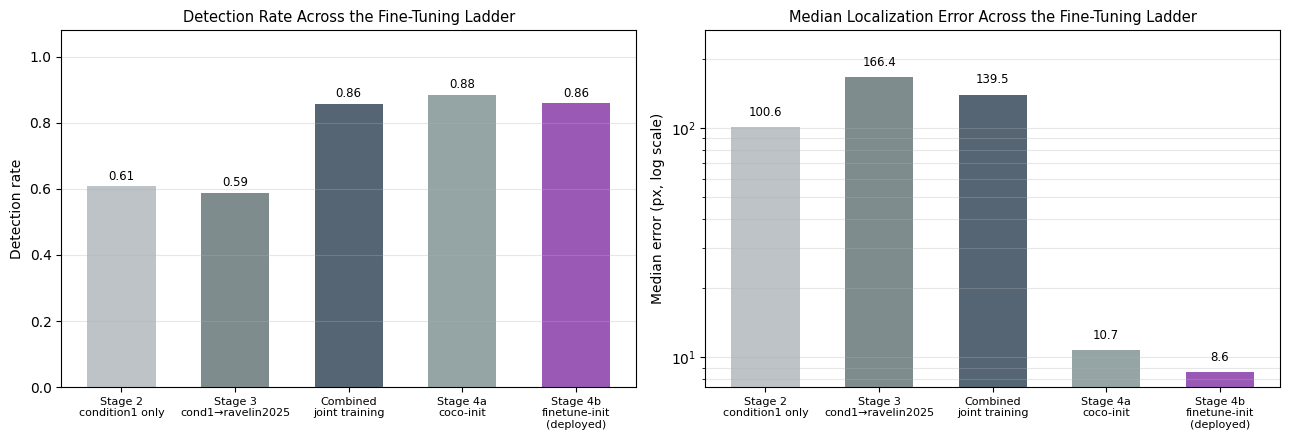

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = [LADDER_COLORS[s] for s in LADDER_STAGES]
xpos = range(len(LADDER_STAGES))
xticklabels = [LADDER_LABELS[s] for s in LADDER_STAGES]

# Detection rate — linear axis
vals = df_ladder['det_rate'].values
bars = axes[0].bar(xpos, vals, color=colors, width=0.6)
for bar, v in zip(bars, vals):
    if pd.notna(v):
        axes[0].text(bar.get_x() + bar.get_width() / 2, v + 0.02, f'{v:.2f}', ha='center', fontsize=8.5)
axes[0].set_xticks(xpos); axes[0].set_xticklabels(xticklabels, fontsize=8)
axes[0].set_ylabel('Detection rate')
axes[0].set_ylim(0, 1.08)
axes[0].set_title('Detection Rate Across the Fine-Tuning Ladder', fontsize=10.5)
axes[0].grid(axis='y', alpha=0.3)

# Median pixel error — log axis: baselines (~100-166px) and target-domain models
# (~9-11px) differ by roughly an order of magnitude and would otherwise squash to
# invisible slivers on a linear scale.
vals = df_ladder['med_err_px'].values
bars = axes[1].bar(xpos, vals, color=colors, width=0.6)
for bar, v in zip(bars, vals):
    if pd.notna(v):
        axes[1].text(bar.get_x() + bar.get_width() / 2, v * 1.12, f'{v:.1f}', ha='center', fontsize=8.5)
axes[1].set_yscale('log')
axes[1].set_ylim(top=max(vals) * 1.6)  # headroom so the tallest bar's label isn't clipped
axes[1].set_xticks(xpos); axes[1].set_xticklabels(xticklabels, fontsize=8)
axes[1].set_ylabel('Median error (px, log scale)')
axes[1].set_title('Median Localization Error Across the Fine-Tuning Ladder', fontsize=10.5)
axes[1].grid(axis='y', alpha=0.3, which='both')

plt.tight_layout()
plt.savefig(OUT / 'keypoint_ladder_progression.png', dpi=150, bbox_inches='tight')
plt.show()


**Discussion.**
- The dominant jump in the ladder is baseline -> target-domain, not init strategy:
  median pixel error drops by roughly an order of magnitude (100-166px for Stages
  2/3/Combined -> 8.6-10.7px for Stages 4a/4b) the moment any tb2026 data enters
  training, regardless of which cross-stadium recipe preceded it.
- Detection rate is not a reliable ranking signal even among the baselines
  themselves: Combined has by far the highest baseline det_rate (0.858) but a
  worse median error than Stage 2 (139.5px vs. 100.6px) — the same disconnect
  between det_rate and localization quality that motivated using median error as
  the primary metric shows up here too, not just in the final model comparison.
- Stage 3 is the weakest point on the entire ladder by every metric (det_rate
  0.587, median 166.4px), reinforcing that naive sequential fine-tuning without
  target-domain grounding can actively hurt rather than help.
- Stage 4a vs. 4b isolates what cross-stadium initialization specifically buys
  once target-domain data is available: both see identical tb2026 training data,
  and 4b's lower median error (8.6px vs. 10.7px) despite a slightly lower det_rate
  is the direct justification for the deployed model's four-stage transfer chain
  — though this gap is far smaller than the baseline-to-target jump, confirming
  that having tb2026 data at all matters more than which weights it starts from.


## 4. Homography Estimation — Field Registration Accuracy

**Method.** `evaluation/evaluate_homography.py` — builds on the keypoint accuracy
above to answer RQ2 directly (registration accuracy, not just component-level
keypoint error). Two experiments per quarter/config:
- *Player-projection error*: the subset of frames with GT player boxes
  (`Data/Players/annotations/tb2026/`, paired with GT keypoints via each clip's
  presnap frame from `tb2026_dataset_metadata.csv`). Computes `H_gt` (from GT
  keypoints) and `H_pred` (from predicted keypoints), projects each GT player's
  foot point through both, and measures the distance between the two projections
  in yards — isolating the registration error attributable to imperfect keypoint
  detection (player detection held at ground truth).
- *Keypoint field-space error*: every test frame, no player data needed. Every
  keypoint's true field position is known a priori (fixed field template), so this
  fits `H_gt` from the GT keypoints, projects each *predicted* keypoint through
  that same `H_gt`, and compares to its known true position — the same
  pixel-space error from Sections 1-3, re-expressed in yards at full test-set size.
- *Confidence-threshold sweep*: reruns the keypoint field-space experiment at
  thresholds 0.10-0.70 to see how fewer/higher-confidence correspondence points
  trade off against homography quality.

**Why.** Component-level keypoint accuracy (Sections 1-3) only partially answers
RQ2 — this measures what actually matters for a bird's-eye minimap: how far off is
a player's projected position, in real-world units.


In [10]:
HOMOG_CONFIGS = [
    ('coco-init (quarter_kfold)', 'quarter_kfold_results_1280'),
    ('finetune-init',             'finetune_quarter_results_1280'),
]

rows = []
for label, family in HOMOG_CONFIGS:
    for q in QUARTERS:
        d = load_json(f'{family}/{q}/train/homography_eval.json')
        if not d:
            continue
        pp, kf = d['player_projection'], d['keypoint_field_error']
        rows.append({
            'Config': label, 'Quarter': q,
            'PlayerProj med (yd)': pp['med_err_yd'], 'PlayerProj p90 (yd)': pp['p90_err_yd'],
            'KptField med (yd)':   kf['med_err_yd'], 'KptField p90 (yd)':   kf['p90_err_yd'],
        })
df_homog = pd.DataFrame(rows).set_index(['Config', 'Quarter'])
df_homog


PlayerProj med (yd)  PlayerProj p90 (yd)  \
Config                    Quarter                                             
coco-init (quarter_kfold) Q1                     0.836                2.931   
                          Q2                     1.494               10.381   
                          Q3                     0.956                3.362   
                          Q4                     0.750                2.150   
finetune-init             Q1                     0.939                3.778   
                          Q2                     0.682                2.207   
                          Q3                     0.640                2.925   
                          Q4                     0.571                1.618   

                                   KptField med (yd)  KptField p90 (yd)  
Config                    Quarter                                        
coco-init (quarter_kfold) Q1                   0.931              3.613  
                          Q2                   1.674             16.221  
                          Q3                   1.030              3.692  
                          Q4                   0.937              2.992  
finetune-init             Q1                   1.024              3.449  
                          Q2                   0.818              2.934  
                          Q3                   0.948              2.997  
                          Q4                   0.746              2.315

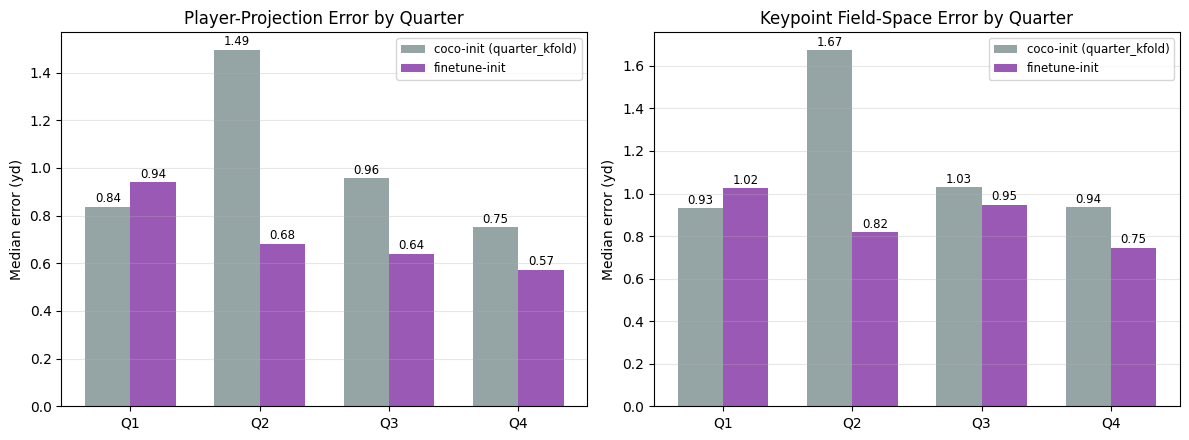

In [11]:
CONFIG_COLORS = {'coco-init (quarter_kfold)': INIT_COLORS['coco'], 'finetune-init': INIT_COLORS['finetune']}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(QUARTERS))
width = 0.35

for metric, ax, ylabel, title in [
    ('PlayerProj med (yd)', axes[0], 'Median error (yd)', 'Player-Projection Error by Quarter'),
    ('KptField med (yd)',   axes[1], 'Median error (yd)', 'Keypoint Field-Space Error by Quarter'),
]:
    for i, (label, _) in enumerate(HOMOG_CONFIGS):
        offset = (i - 0.5) * width
        sub = df_homog.xs(label, level='Config').reindex(QUARTERS)
        ax.bar(x + offset, sub[metric], width, label=label, color=CONFIG_COLORS[label])
        for xi, v in zip(x + offset, sub[metric]):
            if pd.notna(v):
                ax.text(xi, v + 0.02, f'{v:.2f}', ha='center', fontsize=8.5)
    ax.set_xticks(x); ax.set_xticklabels(QUARTERS)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8.5)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'homography_error_by_quarter.png', dpi=150, bbox_inches='tight')
plt.show()


In [12]:
sweep_rows = []
for label, family in HOMOG_CONFIGS:
    per_thresh = {}
    for q in QUARTERS:
        d = load_json(f'{family}/{q}/train/homography_eval.json')
        if not d:
            continue
        for row in d['threshold_sweep']:
            per_thresh.setdefault(row['conf'], []).append(row)
    for conf, rows_ in sorted(per_thresh.items()):
        sweep_rows.append({
            'Config': label, 'conf': conf,
            'det_rate': np.mean([r['det_rate'] for r in rows_]),
            'med_err_yd': np.mean([r['med_err_yd'] for r in rows_]),
            'avg_n_correspondences': np.mean([r['avg_n_correspondences'] for r in rows_]),
        })
df_sweep = pd.DataFrame(sweep_rows)
df_sweep.set_index(['Config', 'conf'])


det_rate  med_err_yd  avg_n_correspondences
Config                    conf                                             
coco-init (quarter_kfold) 0.10  0.939650     1.22025                 25.050
                          0.25  0.884675     1.14300                 21.825
                          0.40  0.817225     1.08475                 19.300
                          0.55  0.746450     1.02175                 17.075
                          0.70  0.647825     0.96025                 14.550
                          0.80  0.554150     0.90100                 12.275
                          0.85  0.492325     0.85675                 10.875
                          0.90  0.411700     0.79650                  9.050
                          0.95  0.267175     0.71125                  5.825
finetune-init             0.10  0.932125     0.93850                 23.975
                          0.25  0.859650     0.88400                 20.650
                          0.40  0.796400     0.84900                 18.450
                          0.55  0.729625     0.82000                 16.625
                          0.70  0.642100     0.78200                 14.500
                          0.80  0.555075     0.73675                 12.500
                          0.85  0.484350     0.71125                 10.875
                          0.90  0.387700     0.68275                  8.675
                          0.95  0.212250     0.61450                  4.750

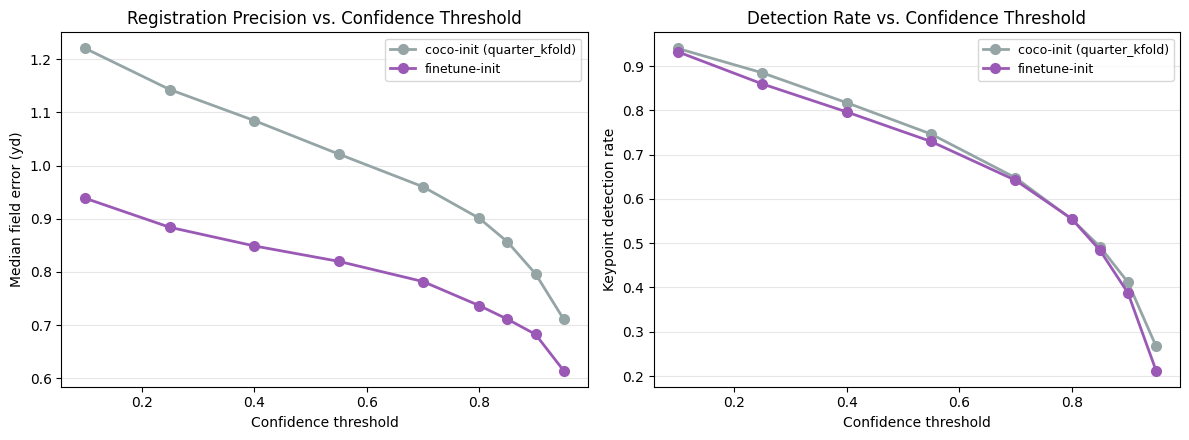

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for label, _ in HOMOG_CONFIGS:
    sub = df_sweep[df_sweep['Config'] == label].sort_values('conf')
    axes[0].plot(sub['conf'], sub['med_err_yd'], marker='o', color=CONFIG_COLORS[label],
                 linewidth=2, markersize=7, label=label)
    axes[1].plot(sub['conf'], sub['det_rate'], marker='o', color=CONFIG_COLORS[label],
                 linewidth=2, markersize=7, label=label)

axes[0].set_xlabel('Confidence threshold'); axes[0].set_ylabel('Median field error (yd)')
axes[0].set_title('Registration Precision vs. Confidence Threshold')
axes[1].set_xlabel('Confidence threshold'); axes[1].set_ylabel('Keypoint detection rate')
axes[1].set_title('Detection Rate vs. Confidence Threshold')
for ax in axes:
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'homography_threshold_sweep.png', dpi=150, bbox_inches='tight')
plt.show()


In [14]:
corr_rows = []
for label, family in HOMOG_CONFIGS:
    for q in QUARTERS:
        d = load_json(f'{family}/{q}/train/homography_eval.json')
        if not d:
            continue
        for row in d['threshold_sweep']:
            corr_rows.append({'Config': label, 'Quarter': q, 'conf': row['conf'],
                               'avg_n_correspondences': row['avg_n_correspondences'],
                               'det_rate': row['det_rate']})
df_corr = pd.DataFrame(corr_rows)
df_corr[df_corr['conf'] >= 0.8].pivot_table(index=['Config', 'conf'], columns='Quarter',
                                             values='avg_n_correspondences')


Quarter                           Q1    Q2    Q3    Q4
Config                    conf                        
coco-init (quarter_kfold) 0.80  13.2   8.1  14.5  13.3
                          0.85  11.9   6.4  13.4  11.8
                          0.90   9.8   4.9  11.9   9.6
                          0.95   5.9   2.9   8.7   5.8
finetune-init             0.80  13.1  12.7  11.9  12.3
                          0.85  11.3  10.8  10.6  10.8
                          0.90   8.9   8.3   8.7   8.8
                          0.95   4.9   4.3   5.2   4.6

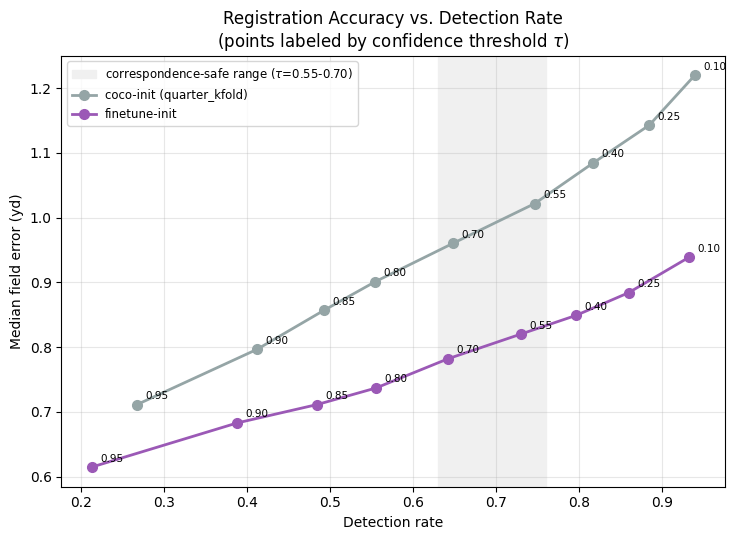

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))

# Correspondence-collapse-safe window (det_rate range spanned by conf in [0.55, 0.70]
# across both configs), shaded for orientation only -- NOT a recommendation, since the
# error curve itself has no elbow (see Discussion below). This is just where correspondence
# counts stay clear of the 4-point failure floor in every quarter.
ax.axvspan(0.63, 0.76, color='#f0f0f0', zorder=0, label='correspondence-safe range ($\\tau$=0.55-0.70)')

for label, _ in HOMOG_CONFIGS:
    sub = df_sweep[df_sweep['Config'] == label].sort_values('conf')
    ax.plot(sub['det_rate'], sub['med_err_yd'], marker='o', color=CONFIG_COLORS[label],
            linewidth=2, markersize=7, label=label, zorder=3)
    for _, row in sub.iterrows():
        ax.annotate(f"{row['conf']:.2f}", (row['det_rate'], row['med_err_yd']),
                    textcoords="offset points", xytext=(6, 4), fontsize=7.5)

ax.set_xlabel('Detection rate')
ax.set_ylabel('Median field error (yd)')
ax.set_title('Registration Accuracy vs. Detection Rate\n(points labeled by confidence threshold $\\tau$)')
ax.legend(fontsize=8.5)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'homography_pareto.png', dpi=150, bbox_inches='tight')
plt.show()


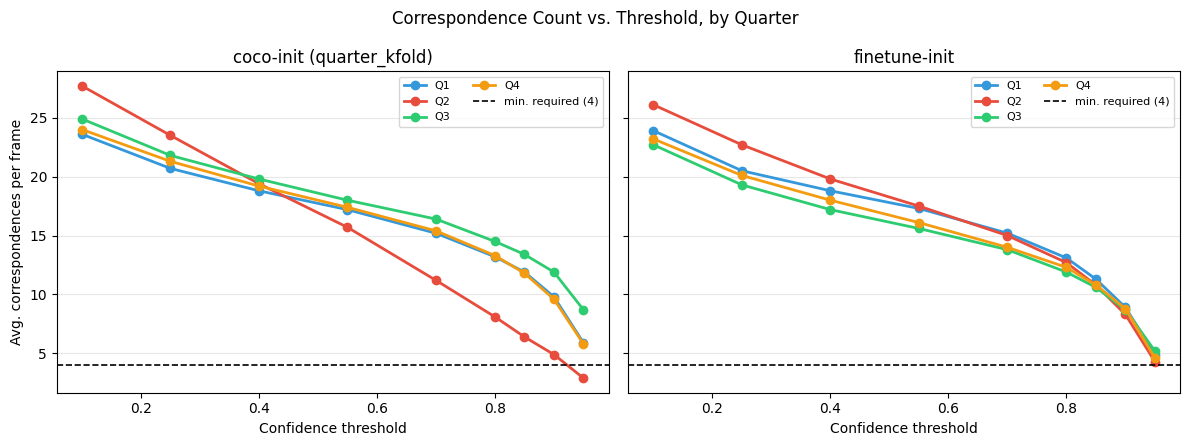

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, (label, _) in zip(axes, HOMOG_CONFIGS):
    for q in QUARTERS:
        sub = df_corr[(df_corr['Config'] == label) & (df_corr['Quarter'] == q)].sort_values('conf')
        ax.plot(sub['conf'], sub['avg_n_correspondences'], marker='o', color=QTR_COLORS[q],
                linewidth=2, markersize=6, label=q)
    ax.axhline(4, color='black', linestyle='--', linewidth=1.2, label='min. required (4)')
    ax.set_xlabel('Confidence threshold')
    ax.set_title(label)
    ax.legend(fontsize=8, ncol=2)
    ax.grid(axis='y', alpha=0.3)

axes[0].set_ylabel('Avg. correspondences per frame')
fig.suptitle('Correspondence Count vs. Threshold, by Quarter')
plt.tight_layout()
plt.savefig(OUT / 'homography_correspondence_collapse.png', dpi=150, bbox_inches='tight')
plt.show()


**Discussion.**
- Registration accuracy is strong overall: sub-1.5 yard median error on a 120-yard
  field for both configs, in most quarters — averaged over quarters, player-projection
  median error is 1.01yd (coco-init) vs. 0.71yd (finetune-init); keypoint field-space
  median error is 1.14yd (coco-init) vs. 0.88yd (finetune-init).
- **finetune-init wins on registration, not just raw keypoint error**: it beats
  coco-init's median on 3/4 quarters and has a far tighter tail everywhere
  (avg p90 2.63yd vs. 4.71yd for player-projection; 2.92yd vs. 6.63yd for
  keypoint field-space). coco-init's Q2 fold is a clear instability outlier
  (p90 10.4yd / 16.2yd) — some frames there hit a degenerate-correspondence
  failure mode (visible keypoints clustered on one side of the field produce a
  numerically unstable homography that blows up projections for points far from
  those correspondences). finetune-init doesn't show this instability in any
  quarter.
- **Extended confidence-threshold sweep (0.10-0.95)**: median registration error
  keeps improving all the way to 0.95 for both configs, with no elbow anywhere in
  the tested range. That absence of an elbow matters: it means there is no point
  where the sweep itself says "stop here, further gains aren't worth it" — accuracy
  alone never identifies an optimal $\tau$.
- **The correspondence-collapse plot shows why the improvement at high $\tau$ is not
  fully real**: at $\tau=0.95$, Q2 alone averages just ~2.9 correspondences per
  frame for coco-init, under the 4-point minimum needed to fit a homography at
  all — visibly crossing the reference line in the chart above. The reported
  median error at high thresholds is computed only over frames that still
  produced a valid fit, so part of the apparent improvement is hard frames
  silently dropping out of the statistic (survivorship bias), not a genuine
  accuracy gain applicable to every frame.
- **No single $\tau$ is clearly optimal from this sweep.** The shaded band in the
  Pareto plot ($\tau\approx0.55$-$0.70$) marks where correspondence counts stay
  safely above the failure floor in every quarter, but it is not a recommendation
  derived from the accuracy curve, since that curve has no elbow to derive one
  from. The deployed pipeline keeps the default $\tau=0.25$ instead: it already
  achieves sub-yard registration error and admits more correspondences per frame
  than a higher threshold would, favoring a more overdetermined, reliable
  per-frame fit over the small, partly-illusory accuracy gains further up the
  sweep.
- **Bridge to Ch. 6 recommendation**: this changes the "best model" framing from
  Section 3's raw keypoint numbers — finetune-init's precision advantage carries
  through to the actual registration task, reinforcing it as the recommended
  configuration despite its slightly lower detection rate.


## 5. Homography Estimation — Data-Scaling Learning Curve

**Method.** Reruns the homography evaluation (`evaluate_homography.py`) against
every checkpoint from the Section 2 data-scaling learning curve
(`quarter_lc_results_1280/{Q}/{LEVEL}/`), instead of only the full-data (3.0Q)
models evaluated in Section 4 above. Same two experiments as Section 4
(player-projection error, keypoint field-space error), at the default confidence
threshold (0.25), across training levels 0.5Q-3.0Q per quarter.

**Why.** Section 2 already showed how *keypoint* detection rate scales with
training-data volume. This asks the same question one level downstream: how much
TB2026 data is actually needed before *registration* becomes usable, since a
homography can fail in ways a per-keypoint det_rate number doesn't capture
directly (e.g. a sparse or poorly-distributed set of correct keypoints can still
produce a numerically unstable fit).


In [17]:
rows = []
for q in QUARTERS:
    for lvl in LEVELS:
        d = load_json(f'quarter_lc_results_1280/{q}/{lvl}/homography_eval.json')
        if not d:
            continue
        pp, kf = d['player_projection'], d['keypoint_field_error']
        rows.append({
            'Quarter': q, 'Level': lvl,
            'PlayerProj med (yd)': pp['med_err_yd'],
            'KptField med (yd)':   kf['med_err_yd'],
        })
df_lc_homog = pd.DataFrame(rows)
df_lc_homog.pivot(index='Level', columns='Quarter', values='KptField med (yd)').reindex(LEVELS)


Quarter,Q1,Q2,Q3,Q4
Level,,,,
0.5Q,4.634,6.374,8.147,7.162
1.0Q,4.591,5.894,8.516,8.257
1.5Q,1.817,4.354,3.221,6.873
2.0Q,1.436,3.164,1.492,1.106
2.5Q,0.965,2.772,1.205,1.020
3.0Q,0.932,1.674,1.030,0.878


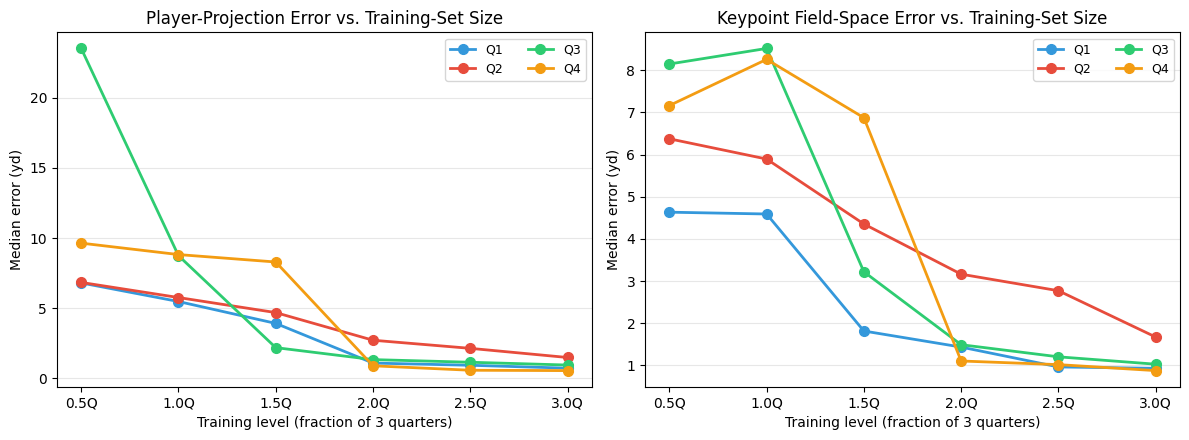

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(LEVELS))

for q in QUARTERS:
    sub = df_lc_homog[df_lc_homog['Quarter'] == q].set_index('Level').reindex(LEVELS)
    axes[0].plot(x, sub['PlayerProj med (yd)'], marker='o', color=QTR_COLORS[q],
                 linewidth=2, markersize=7, label=q)
    axes[1].plot(x, sub['KptField med (yd)'], marker='o', color=QTR_COLORS[q],
                 linewidth=2, markersize=7, label=q)

for ax, ylabel, title in [
    (axes[0], 'Median error (yd)', 'Player-Projection Error vs. Training-Set Size'),
    (axes[1], 'Median error (yd)', 'Keypoint Field-Space Error vs. Training-Set Size'),
]:
    ax.set_xticks(x); ax.set_xticklabels(LEVELS)
    ax.set_xlabel('Training level (fraction of 3 quarters)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=9, ncol=2)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'homography_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()


### Thesis Figure — Combined Keypoint + Registration Learning Curve

Single figure combining the Section 2 (keypoint) and Section 5 (homography)
data-scaling curves, det_rate panels dropped since median error is the metric
that matters for this argument. Used as `fig:learning_curve` in the thesis,
referenced from both the Keypoint Detection Evaluation and Homography
Estimation Evaluation Results paragraphs.

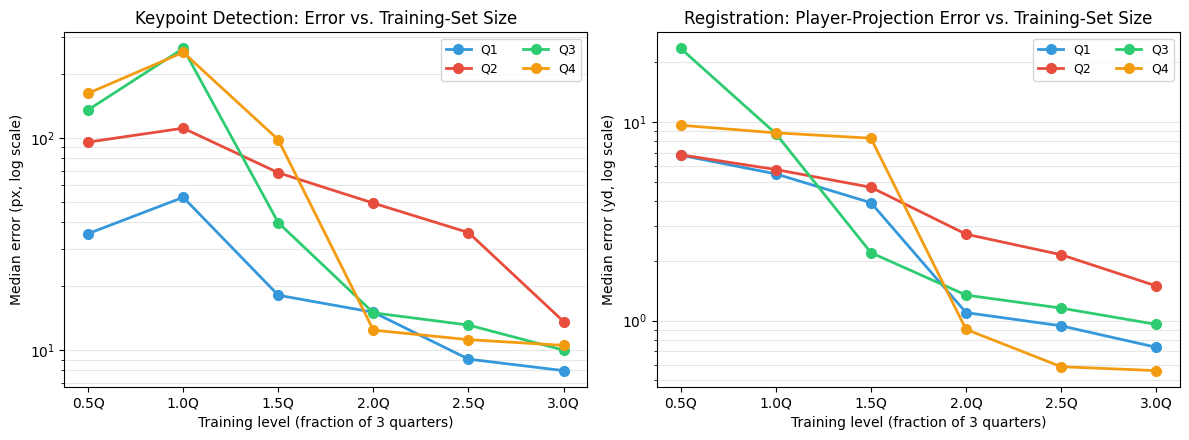

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(LEVELS))

for q in QUARTERS:
    sub_kpt = df_lc[df_lc['Quarter'] == q].set_index('Level').reindex(LEVELS)
    axes[0].plot(x, sub_kpt['med_err_px'], marker='o', color=QTR_COLORS[q],
                 linewidth=2, markersize=7, label=q)

    sub_homog = df_lc_homog[df_lc_homog['Quarter'] == q].set_index('Level').reindex(LEVELS)
    axes[1].plot(x, sub_homog['PlayerProj med (yd)'], marker='o', color=QTR_COLORS[q],
                 linewidth=2, markersize=7, label=q)

axes[0].set_yscale('log')
axes[0].set_xticks(x); axes[0].set_xticklabels(LEVELS)
axes[0].set_xlabel('Training level (fraction of 3 quarters)')
axes[0].set_ylabel('Median error (px, log scale)')
axes[0].set_title('Keypoint Detection: Error vs. Training-Set Size')
axes[0].legend(fontsize=9, ncol=2)
axes[0].grid(axis='y', alpha=0.3, which='both')

axes[1].set_yscale('log')
axes[1].set_xticks(x); axes[1].set_xticklabels(LEVELS)
axes[1].set_xlabel('Training level (fraction of 3 quarters)')
axes[1].set_ylabel('Median error (yd, log scale)')
axes[1].set_title('Registration: Player-Projection Error vs. Training-Set Size')
axes[1].legend(fontsize=9, ncol=2)
axes[1].grid(axis='y', alpha=0.3, which='both')

plt.tight_layout()
plt.savefig(OUT / 'keypoint_homography_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()


**Discussion.**
- Registration accuracy shows a much sharper data-volume threshold than the raw
  keypoint det_rate curve in Section 2 suggested. Q3 and Q4 both have a dramatic
  knee: Q4's player-projection median error drops from ~8.3yd at 1.5Q to 0.9yd at
  2.0Q, a step change rather than a gradual improvement, even though Section 2's
  own det_rate curve for Q4 only moves from 0.81 to 0.85 over that same interval.
- This lines up with the instability failure mode already flagged in Section 4:
  below a certain amount of training data, detections are sparse or unevenly
  distributed enough that the fitted homography becomes numerically unstable,
  producing wild projection errors even when det_rate itself looks reasonable.
  Once enough data is available, this instability disappears abruptly rather
  than fading out gradually.
- Q1 and Q2 don't show as sharp a knee, improving more gradually across all six
  levels, so this effect is fold-dependent rather than a fixed property of the
  training pipeline. [ ] Worth checking whether the knee quarters (Q3, Q4) share
  some property (fewer clips, different lighting/camera angle) that makes them
  more sensitive to limited data.
- **Practical implication for the thesis**: raw keypoint det_rate is not a
  reliable proxy for how much data is "enough" for a usable registration
  pipeline. The homography-level metric here, not the keypoint-level one from
  Section 2, should be the one that answers "how much TB2026 data is needed."


## 6. Summary

**Main-eval config vs. the old cross-stadium approach vs. the CV ceiling.**
Mirrors the closing comparison in `Player_Detection/evaluation.ipynb` (best model vs.
k-fold upper bound) — here comparing the recommended quarter-based config against
(a) the best result from the additional-experiments cross-stadium chapter, and (b)
`upper_bound_results`, an old-style random 5-fold CV on TB2026 that serves as a
rough ceiling reference (not a fair generalization measure — same caveat as the
player-detection notebook's upper bound).


In [20]:
def avg_over_folds(pattern, keys):
    vals = [kpt_overall(pattern.format(f)) for f in range(4)]
    vals = [v for v in vals if v]
    return {k: np.mean([v[k] for v in vals]) for k in keys} if vals else {}

def avg_over_quarters(pattern, keys):
    vals = [kpt_overall(pattern.format(q)) for q in QUARTERS]
    vals = [v for v in vals if v]
    return {k: np.mean([v[k] for v in vals]) for k in keys} if vals else {}

KEYS = ['det_rate', 'mean_err_px', 'med_err_px']

rows = [
    {'Config': 'Old approach: Stage 3 (cross-stadium, fixed TB2026 test set)',
     **(kpt_overall('cross_stadium_results/3/train/kpt_eval.json') or {})},
    {'Config': 'Old approach: Combined joint training (fixed TB2026 test set)',
     **(kpt_overall('combined_results/train/kpt_eval.json') or {})},
    {'Config': 'Main eval: quarter_kfold @ 1280px (avg over 4 folds)',
     **avg_over_quarters('quarter_kfold_results_1280/{}/kpt_eval.json', KEYS)},
    {'Config': 'Main eval: finetune-init @ 1280px (avg over 4 folds)',
     **avg_over_quarters('finetune_quarter_results_1280/{}/kpt_eval.json', KEYS)},
    {'Config': 'Reference ceiling: upper_bound 5-fold CV (avg over folds)',
     **avg_over_folds('upper_bound_results/fold_{}/kpt_eval.json', KEYS)},
]
df_summary = pd.DataFrame(rows).set_index('Config')[KEYS]
df_summary


,det_rate,mean_err_px,med_err_px
Config,,,
"Old approach: Stage 3 (cross-stadium, fixed TB2026 test set)",0.587300,341.2500,166.4000
Old approach: Combined joint training (fixed TB2026 test set),0.857800,260.7600,139.4600
Main eval: quarter_kfold @ 1280px (avg over 4 folds),0.884650,59.5925,10.7275
Main eval: finetune-init @ 1280px (avg over 4 folds),0.859575,31.7825,8.5975
Reference ceiling: upper_bound 5-fold CV (avg over folds),0.921050,75.2400,9.3400


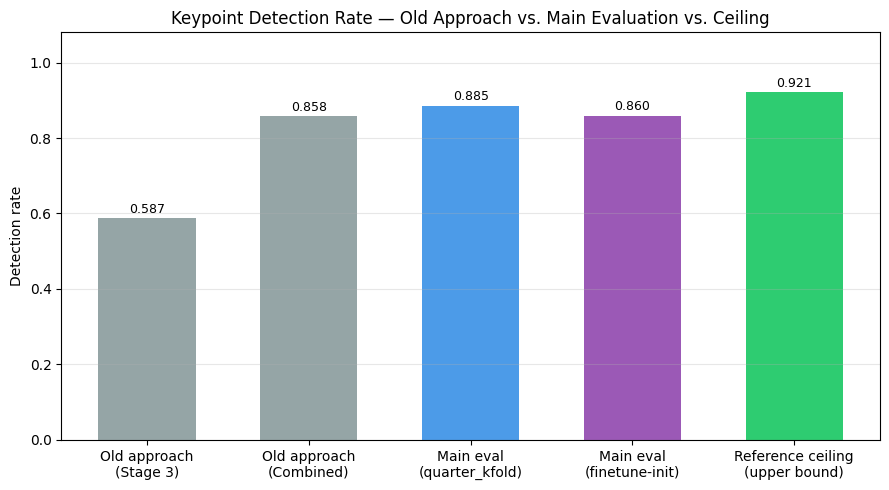

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
labels = ['Old approach\n(Stage 3)', 'Old approach\n(Combined)',
          'Main eval\n(quarter_kfold)', 'Main eval\n(finetune-init)',
          'Reference ceiling\n(upper bound)']
colors = ['#95a5a6', '#95a5a6', '#4C9BE8', '#9b59b6', '#2ecc71']
vals = df_summary['det_rate'].values

bars = ax.bar(labels, vals, color=colors, width=0.6)
for bar, v in zip(bars, vals):
    if pd.notna(v):
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.015, f'{v:.3f}', ha='center', fontsize=9)
ax.set_ylabel('Detection rate')
ax.set_ylim(0, 1.08)
ax.set_title('Keypoint Detection Rate — Old Approach vs. Main Evaluation vs. Ceiling')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / 'summary_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


**Discussion.**
- Headline "why we changed approach" number: old-approach Stage 3 det_rate 0.587 vs.
  the quarter-based main-eval configs at 0.860-0.885 — roughly +0.27-0.30 det_rate,
  and mean localization error drops by nearly an order of magnitude (341px -> ~32-60px).
  Even the old approach's best variant (Combined joint training, 0.858 det_rate,
  260.8px mean error) still trails both main-eval configs on error, and is roughly on
  par with finetune-init on det_rate — the quarter-based methodology change itself
  (homogeneous per-quarter folds vs. the old fixed/mixed TB2026 test set) looks like
  the dominant factor, not just more data.
- Reference ceiling (upper_bound, random 5-fold CV) has the highest det_rate (0.921)
  but *worse* mean error (75.2px) than either main-eval config — likely because
  random folds mix all quarters into train/val, which can hide fold-specific
  lighting/angle effects that quarter-holdout folds expose. Worth flagging this
  inversion explicitly rather than treating upper_bound as a strictly better ceiling.
- **RQ2 headline (Section 4)**: the homography-level evaluation confirms and
  sharpens this picture — finetune-init achieves 0.71-0.88 yard median registration
  error on a 120-yard field (vs. 1.01-1.14yd for coco-init/quarter_kfold), with a
  much tighter error tail. This is the number that actually answers RQ2, and it
  favors finetune-init over the higher-det_rate quarter_kfold config, so the
  thesis's recommended configuration should be finetune-init, not the config with
  the best raw keypoint det_rate.
- [ ] For the thesis: quantify headroom between quarter_kfold (0.885 det_rate) and
  the ceiling (0.921), while noting the fold-construction caveat (random CV is not
  a fair generalization test, same caveat as the player-detection notebook).
